In [ ]:
import numpy as np
import pandas as pd
!pip install --upgrade scikit-learn
from sklearn.datasets import load_iris
from sklearn import tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import RepeatedStratifiedKFold
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt

In [ ]:
iris = load_iris(as_frame=True)

In [ ]:
print(iris.frame.head())
print(iris.frame.describe())

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000  

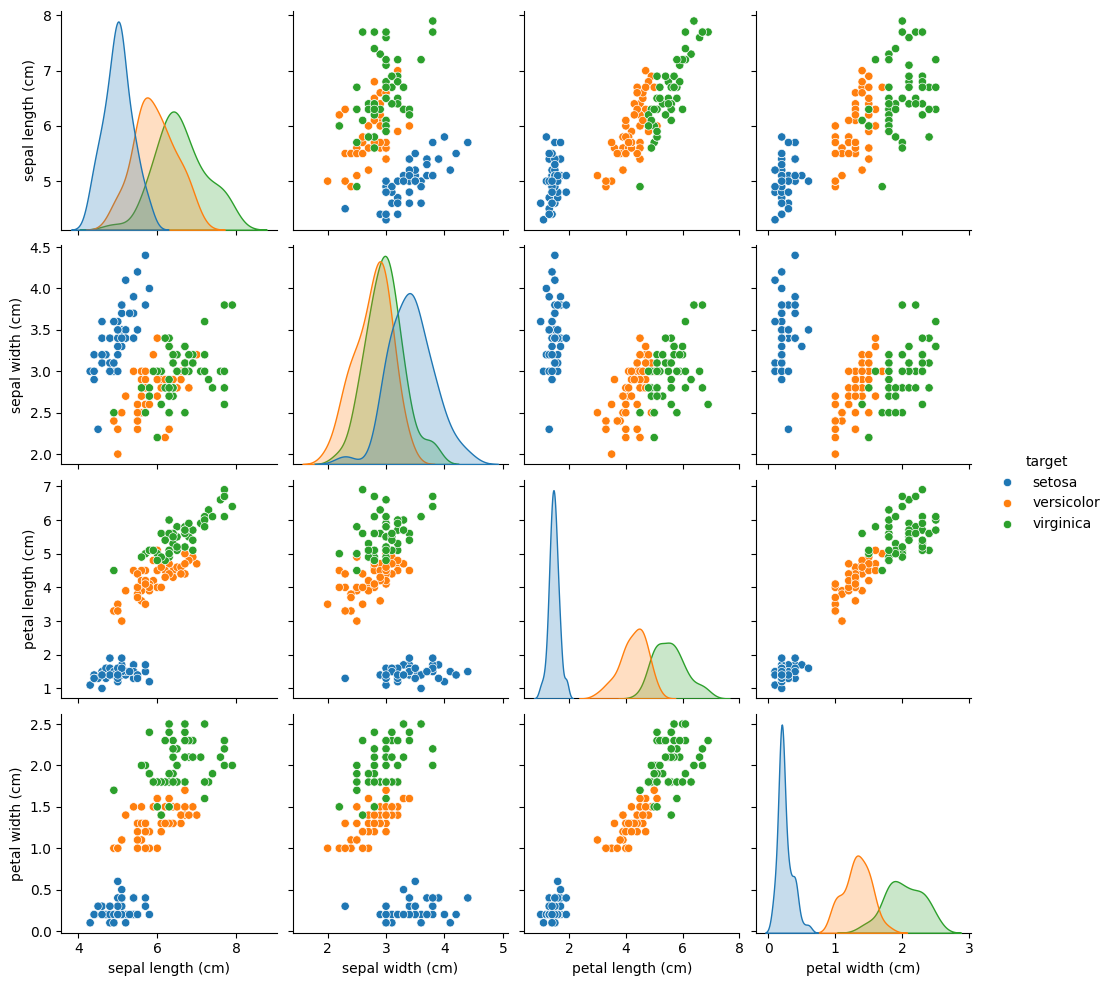

In [ ]:
iris.frame["target"] = iris.target_names[iris.target]
_ = sns.pairplot(iris.frame, hue="target")

Выделяется - setosa

Пересекаются - versicolor и verginica

In [ ]:
X = iris.frame.drop(columns="target")
y = iris.frame["target"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
clf = tree.DecisionTreeClassifier()
clf = clf.fit(X_train, y_train)

[Text(0.4, 0.9166666666666666, 'petal length (cm) <= 2.45\ngini = 0.667\nsamples = 120\nvalue = [40, 40, 40]\nclass = setosa'),
 Text(0.3, 0.75, 'gini = 0.0\nsamples = 40\nvalue = [40, 0, 0]\nclass = setosa'),
 Text(0.35, 0.8333333333333333, 'True  '),
 Text(0.5, 0.75, 'petal width (cm) <= 1.65\ngini = 0.5\nsamples = 80\nvalue = [0, 40, 40]\nclass = versicolor'),
 Text(0.45, 0.8333333333333333, '  False'),
 Text(0.2, 0.5833333333333334, 'petal length (cm) <= 4.95\ngini = 0.133\nsamples = 42\nvalue = [0, 39, 3]\nclass = versicolor'),
 Text(0.1, 0.4166666666666667, 'gini = 0.0\nsamples = 38\nvalue = [0, 38, 0]\nclass = versicolor'),
 Text(0.3, 0.4166666666666667, 'sepal width (cm) <= 2.75\ngini = 0.375\nsamples = 4\nvalue = [0, 1, 3]\nclass = virginica'),
 Text(0.2, 0.25, 'petal length (cm) <= 5.05\ngini = 0.5\nsamples = 2\nvalue = [0, 1, 1]\nclass = versicolor'),
 Text(0.1, 0.08333333333333333, 'gini = 0.0\nsamples = 1\nvalue = [0, 0, 1]\nclass = virginica'),
 Text(0.3, 0.08333333333333

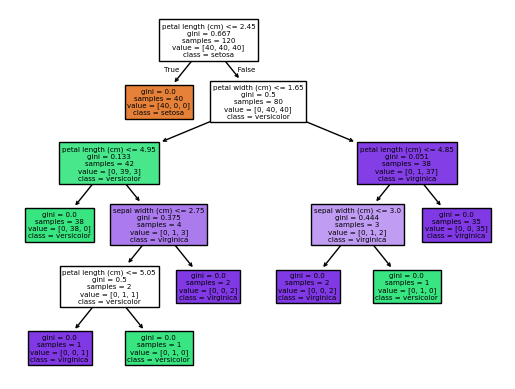

In [ ]:
tree.plot_tree(clf, feature_names=X_train.columns, class_names=clf.classes_, filled=True)

 Первое разбиение отделяет класс setosa т.к. он имеет ярковыраженный petal length

In [ ]:
clf.score(X_train, y_train)

1.0

In [ ]:
clf.score(X_test, y_test)

0.9333333333333333

In [ ]:
rows = []

for i in range(1, 11):
    clf_d = tree.DecisionTreeClassifier(max_depth=i)
    clf_d = clf_d.fit(X_train, y_train)

    train_acc = clf_d.score(X_train, y_train)
    test_acc = clf_d.score(X_test, y_test)
    cross = cross_val_score(clf_d, X, y, cv=5)

    rows.append({"max_depth": i, "train": train_acc, "test": test_acc, "cross_mean": cross.mean(), "cross_std": cross.std()})

accuracy = pd.DataFrame(rows).set_index("max_depth")[["train", "test", "cross_mean", "cross_std"]]
print(accuracy.to_string(index=False))

   train     test  cross_mean  cross_std
0.666667 0.666667    0.666667   0.000000
0.966667 0.933333    0.933333   0.047140
0.983333 0.966667    0.973333   0.024944
0.991667 0.966667    0.953333   0.033993
1.000000 0.933333    0.960000   0.032660
1.000000 0.933333    0.953333   0.033993
1.000000 0.933333    0.960000   0.032660
1.000000 0.966667    0.960000   0.032660
1.000000 0.966667    0.960000   0.032660
1.000000 0.933333    0.960000   0.032660


<Axes: xlabel='max_depth'>

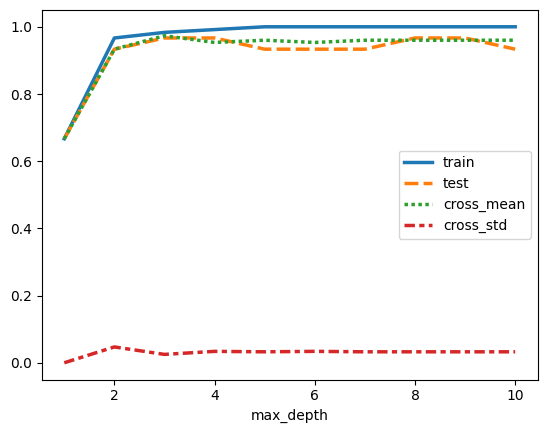

In [ ]:
sns.lineplot(data=accuracy, palette="tab10", linewidth=2.5)

In [ ]:
rows_rs = []

for i in range(10):
    X_train_rs, X_test_rs, y_train_rs, y_test_rs = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=i,
        stratify=y
    )

    clf_rs = tree.DecisionTreeClassifier()
    clf_rs = clf_rs.fit(X_train_rs, y_train_rs)

    test_acc_rs = clf_rs.score(X_test_rs, y_test_rs)
    cross_rs = cross_val_score(clf_rs, X, y, cv=5)
    feature = clf_rs.tree_.feature[0]
    threshold = clf_rs.tree_.threshold[0]

    rows_rs.append({"random_state": i, "feature": feature, "threshold": threshold, "test": test_acc_rs, "cross_std": cross_rs.std()})

instability = pd.DataFrame(rows_rs)
print(instability.to_string(index=False))

 random_state  feature  threshold     test  cross_std
            0        2       2.45 0.966667   0.032660
            1        3       0.75 0.966667   0.036515
            2        2       2.45 0.966667   0.033993
            3        3       0.80 0.900000   0.036515
            4        2       2.45 0.966667   0.032660
            5        3       0.80 0.966667   0.033993
            6        2       2.45 0.933333   0.033993
            7        2       2.60 0.966667   0.036515
            8        3       0.80 0.966667   0.032660
            9        3       0.80 0.933333   0.036515


In [ ]:
X_b = iris.frame.drop(columns=["sepal length (cm)", "sepal width (cm)", "target"])

X_b_train, X_b_test, y_b_train, y_b_test = train_test_split(
    X_b,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
clf_b_1 = tree.DecisionTreeClassifier(max_depth=1)
clf_b_1 = clf_b_1.fit(X_b_train, y_b_train)

clf_b_3 = tree.DecisionTreeClassifier(max_depth=3)
clf_b_3 = clf_b_3.fit(X_b_train, y_b_train)

clf_b_none = tree.DecisionTreeClassifier(max_depth=None)
clf_b_none = clf_b_none.fit(X_b_train, y_b_train)

In [ ]:
def plot_tree_boundary(clf, X, y, title):
    # Создаём координатную сетку
    feature_1, feature_2 = np.meshgrid( np.linspace(X.iloc[:, 0].min(), X.iloc[:, 0].max(), 100), np.linspace(X.iloc[:, 1].min(), X.iloc[:, 1].max(), 100) )
    # Превращаем сетку в список точек
    grid = np.column_stack([
        feature_1.ravel(),
        feature_2.ravel()
    ])

    # DataFrame нужен, чтобы sklearn видел названия признаков
    grid_df = pd.DataFrame(
        grid,
        columns=X.columns
    )

    # Предсказываем
    y_pred = clf.predict(grid_df)

    classes = clf.classes_
    y_pred_numeric = np.searchsorted(classes, y_pred)

    # Явно приводим к числовому массиву
    # y_pred = np.asarray(y_pred, dtype=float)

    # Возвращаем форму сетки
    y_pred_numeric = y_pred_numeric.reshape(feature_1.shape)

    # Создаём display
    display = DecisionBoundaryDisplay(
        xx0=feature_1,
        xx1=feature_2,
        n_classes=len(clf.classes_),
        response=y_pred_numeric
    )

    display.plot()

    y_numeric = np.searchsorted(classes, y)

    # Реальные точки
    display.ax_.scatter(
        X.iloc[:, 0],
        X.iloc[:, 1],
        c=y_numeric,
        cmap=mpl.colors.ListedColormap(display.multiclass_colors_),
        edgecolor="black"
    )

    plt.xlabel(X.columns[0])
    plt.ylabel(X.columns[1])
    plt.title(title)
    plt.show()


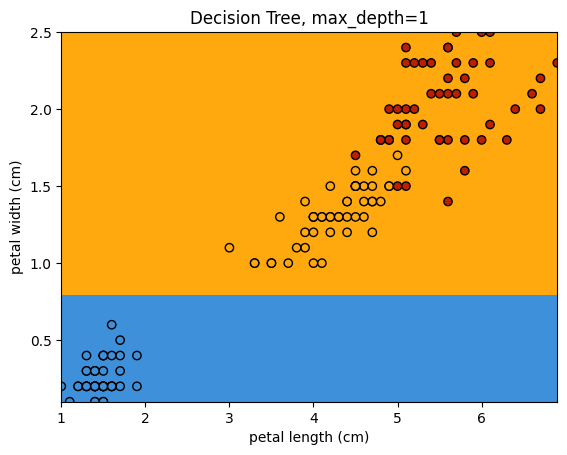

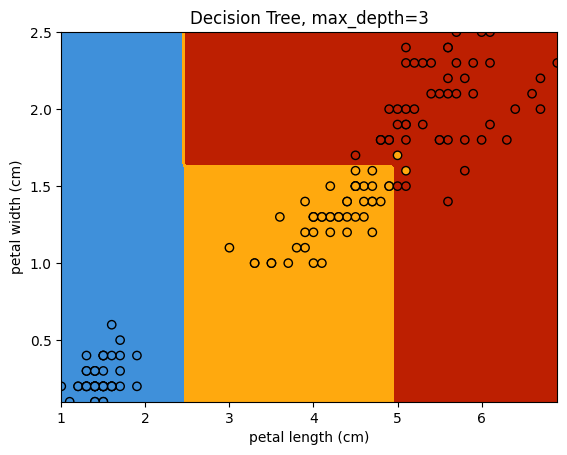

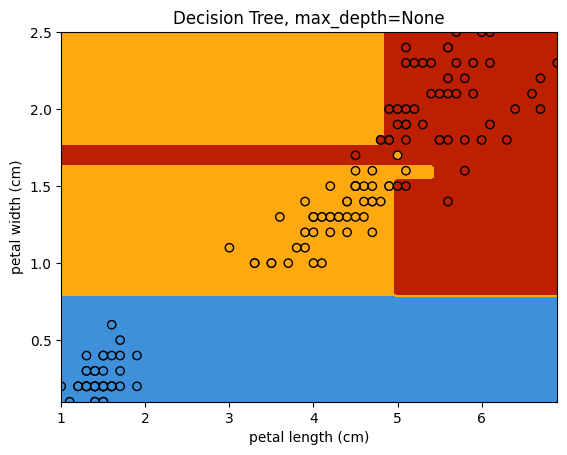

In [ ]:
plot_tree_boundary(
    clf_b_1,
    X_b,
    y,
    "Decision Tree, max_depth=1"
)

plot_tree_boundary(
    clf_b_3,
    X_b,
    y,
    "Decision Tree, max_depth=3"
)

plot_tree_boundary(
    clf_b_none,
    X_b,
    y,
    "Decision Tree, max_depth=None"
)

In [ ]:
clf_msl_1_b = tree.DecisionTreeClassifier(min_samples_leaf=1)
clf_msl_1_b = clf_msl_1_b.fit(X_b_train, y_b_train)

clf_msl_5_b = tree.DecisionTreeClassifier(min_samples_leaf=5)
clf_msl_5_b = clf_msl_5_b.fit(X_b_train, y_b_train)

clf_msl_10_b = tree.DecisionTreeClassifier(min_samples_leaf=10)
clf_msl_10_b = clf_msl_10_b.fit(X_b_train, y_b_train)

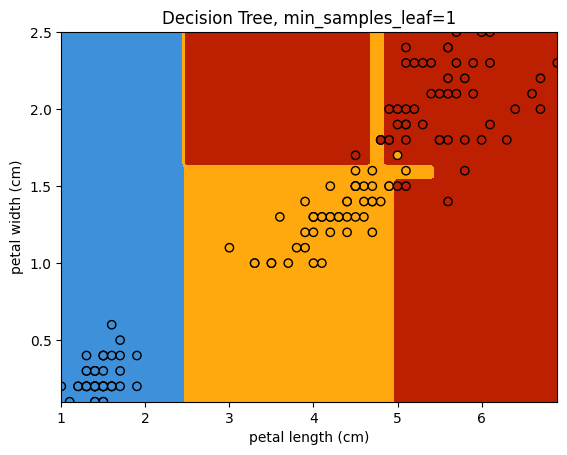

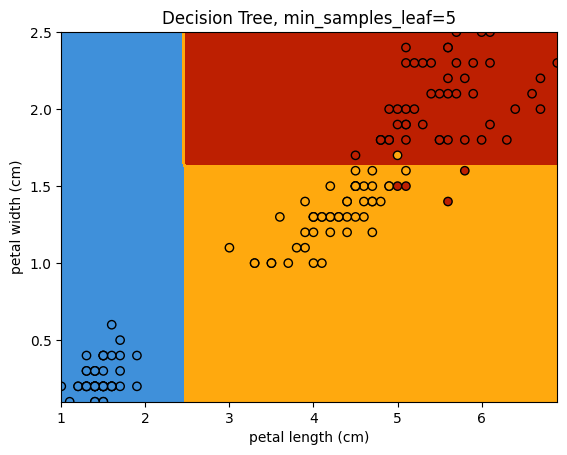

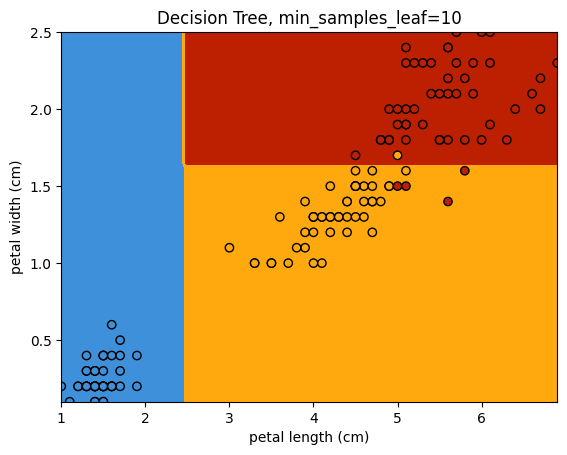

In [ ]:
plot_tree_boundary(
    clf_msl_1_b,
    X_b,
    y,
    "Decision Tree, min_samples_leaf=1"
)

plot_tree_boundary(
    clf_msl_5_b,
    X_b,
    y,
    "Decision Tree, min_samples_leaf=5"
)

plot_tree_boundary(
    clf_msl_10_b,
    X_b,
    y,
    "Decision Tree, min_samples_leaf=10"
)

In [ ]:
clf_msl_1 = tree.DecisionTreeClassifier(min_samples_leaf=1)
clf_msl_1 = clf_msl_1.fit(X_train, y_train)

clf_msl_5 = tree.DecisionTreeClassifier(min_samples_leaf=5)
clf_msl_5 = clf_msl_5.fit(X_train, y_train)

clf_msl_10 = tree.DecisionTreeClassifier(min_samples_leaf=10)
clf_msl_10 = clf_msl_10.fit(X_train, y_train)

In [ ]:
print("CVS MSL1 std:", cross_val_score(clf_msl_1, X, y, cv=5).std(), "CVS MSL1 mean:", cross_val_score(clf_msl_1, X, y, cv=5).mean())
print("CVS MSL5 std:", cross_val_score(clf_msl_5, X, y, cv=5).std(), "CVS MSL5 mean:", cross_val_score(clf_msl_5, X, y, cv=5).mean())
print("CVS MSL10 std:", cross_val_score(clf_msl_10, X, y, cv=5).std(), "CVS MSL10 mean:", cross_val_score(clf_msl_10, X, y, cv=5).mean())

CVS MSL1 std: 0.036514837167011066 CVS MSL1 mean: 0.9600000000000002
CVS MSL5 std: 0.06110100926607785 CVS MSL5 mean: 0.9400000000000001
CVS MSL10 std: 0.04714045207910316 CVS MSL10 mean: 0.9333333333333332


In [ ]:
clf_gini = tree.DecisionTreeClassifier(criterion="gini")
clf_gini = clf_gini.fit(X_train, y_train)

clf_entropy = tree.DecisionTreeClassifier(criterion="entropy")
clf_entropy = clf_entropy.fit(X_train, y_train)

In [ ]:
print(clf_gini.get_depth(), clf_gini.get_n_leaves())
print(clf_entropy.get_depth(), clf_entropy.get_n_leaves())

5 8
5 8


[Text(0.4, 0.9166666666666666, 'petal length (cm) <= 2.45\ngini = 0.667\nsamples = 120\nvalue = [40, 40, 40]\nclass = setosa'),
 Text(0.3, 0.75, 'gini = 0.0\nsamples = 40\nvalue = [40, 0, 0]\nclass = setosa'),
 Text(0.35, 0.8333333333333333, 'True  '),
 Text(0.5, 0.75, 'petal width (cm) <= 1.65\ngini = 0.5\nsamples = 80\nvalue = [0, 40, 40]\nclass = versicolor'),
 Text(0.45, 0.8333333333333333, '  False'),
 Text(0.2, 0.5833333333333334, 'petal length (cm) <= 4.95\ngini = 0.133\nsamples = 42\nvalue = [0, 39, 3]\nclass = versicolor'),
 Text(0.1, 0.4166666666666667, 'gini = 0.0\nsamples = 38\nvalue = [0, 38, 0]\nclass = versicolor'),
 Text(0.3, 0.4166666666666667, 'petal width (cm) <= 1.55\ngini = 0.375\nsamples = 4\nvalue = [0, 1, 3]\nclass = virginica'),
 Text(0.2, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [0, 0, 2]\nclass = virginica'),
 Text(0.4, 0.25, 'sepal length (cm) <= 6.6\ngini = 0.5\nsamples = 2\nvalue = [0, 1, 1]\nclass = versicolor'),
 Text(0.3, 0.08333333333333333, 'gini = 0.0

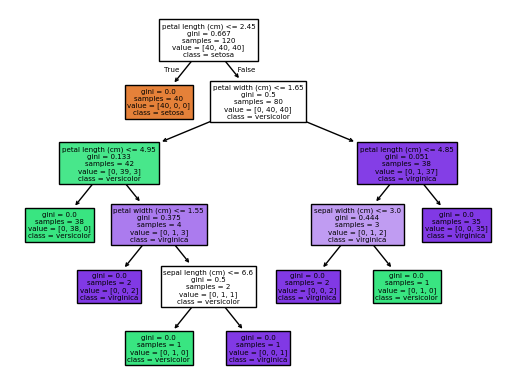

In [ ]:
tree.plot_tree(clf_gini, feature_names=X_train.columns, class_names=clf_gini.classes_, filled=True)

[Text(0.4, 0.9166666666666666, 'petal length (cm) <= 2.45\nentropy = 1.585\nsamples = 120\nvalue = [40, 40, 40]\nclass = setosa'),
 Text(0.3, 0.75, 'entropy = 0.0\nsamples = 40\nvalue = [40, 0, 0]\nclass = setosa'),
 Text(0.35, 0.8333333333333333, 'True  '),
 Text(0.5, 0.75, 'petal width (cm) <= 1.65\nentropy = 1.0\nsamples = 80\nvalue = [0, 40, 40]\nclass = versicolor'),
 Text(0.45, 0.8333333333333333, '  False'),
 Text(0.2, 0.5833333333333334, 'petal length (cm) <= 4.95\nentropy = 0.371\nsamples = 42\nvalue = [0, 39, 3]\nclass = versicolor'),
 Text(0.1, 0.4166666666666667, 'entropy = 0.0\nsamples = 38\nvalue = [0, 38, 0]\nclass = versicolor'),
 Text(0.3, 0.4166666666666667, 'petal width (cm) <= 1.55\nentropy = 0.811\nsamples = 4\nvalue = [0, 1, 3]\nclass = virginica'),
 Text(0.2, 0.25, 'entropy = 0.0\nsamples = 2\nvalue = [0, 0, 2]\nclass = virginica'),
 Text(0.4, 0.25, 'sepal length (cm) <= 6.6\nentropy = 1.0\nsamples = 2\nvalue = [0, 1, 1]\nclass = versicolor'),
 Text(0.3, 0.083333

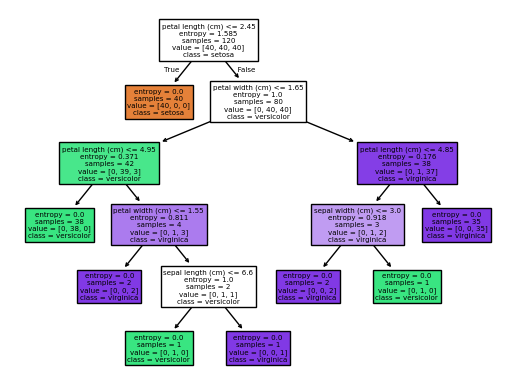

In [ ]:
tree.plot_tree(clf_entropy, feature_names=X_train.columns, class_names=clf_entropy.classes_, filled=True)

In [ ]:
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

print("CVS Gini std:", cross_val_score(clf_gini, X, y, cv=rskf).std(), "CVS Gini mean:", cross_val_score(clf_gini, X, y, cv=rskf).mean())
print("CVS Entropy std:", cross_val_score(clf_entropy, X, y, cv=rskf).std(), "CVS Entropy mean:", cross_val_score(clf_entropy, X, y, cv=rskf).mean())

CVS Gini std: 0.039799497484264784 CVS Gini mean: 0.9406666666666667
CVS Entropy std: 0.04178782385123951 CVS Entropy mean: 0.944


In [ ]:
for i in range(10):
    X_train_rs2, X_test_rs2, y_train_rs2, y_test_rs2 = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=i,
        stratify=y
    )

    clf_rs2 = tree.DecisionTreeClassifier()
    clf_rs2 = clf_rs2.fit(X_train_rs2, y_train_rs2)

    forest_importances = pd.Series(clf_rs2.feature_importances_, index=X_train_rs2.columns)
    print(forest_importances)

sepal length (cm)    0.000000
sepal width (cm)     0.016667
petal length (cm)    0.527976
petal width (cm)     0.455357
dtype: float64
sepal length (cm)    0.000000
sepal width (cm)     0.016667
petal length (cm)    0.429880
petal width (cm)     0.553453
dtype: float64
sepal length (cm)    0.012500
sepal width (cm)     0.029524
petal length (cm)    0.910117
petal width (cm)     0.047859
dtype: float64
sepal length (cm)    0.00000
sepal width (cm)     0.03000
petal length (cm)    0.04192
petal width (cm)     0.92808
dtype: float64
sepal length (cm)    0.000000
sepal width (cm)     0.016667
petal length (cm)    0.912576
petal width (cm)     0.070758
dtype: float64
sepal length (cm)    0.022082
sepal width (cm)     0.016667
petal length (cm)    0.038570
petal width (cm)     0.922682
dtype: float64
sepal length (cm)    0.007500
sepal width (cm)     0.025833
petal length (cm)    0.906015
petal width (cm)     0.060652
dtype: float64
sepal length (cm)    0.00000
sepal width (cm)     0.01250
p